# 8. 中断
**`LangGraph`** 提供了两种中断机制：

- **动态中断**：在图的任意节点中调用 **`interrupt()`** 函数实现

  它可以放在代码的任意位置，并且可以根据应用逻辑设置条件触发，所以是**动态**的。

  动态中断提供了人机交互接口，使得调用者可以人为干预计算图的运行，**是业务逻辑的一部分**。

- **静态中断**：在编译或调用状态图时通过 **`interrupt_before`** 和 **`interrupt_after`** 参数设置断点

  它是在运行前确定的，不能根据业务逻辑条件触发，所以是**静态**的。

  静态中断主要用于调试，**不是业务逻辑的一部分**。

## 8.1  动态中断

1. 当中断触发时，**`LangGraph`** 会通过持久化机制保存当前图状态，并无限期等待直到用户恢复执行。

2. 中断通过在任意图节点中调用 **`interrupt()`** 函数实现，该函数可以接收任何可 **`JSON`** 序列化的值，并将该值暴露给调用方。

3. 中断触发后，调用方根据 **`interrupt()`** 暴露的信息生成反馈，重新调用图时通过 **`Command`** 将反馈传递给计算图，恢复图的运行。

4. 恢复运行后，调用方通过 **`Command`** 传递的反馈会作为 **`interrupt()`** 函数的返回值，参与后续计算。


动态中断存在多种应用场景,下面的小节将会介绍如下模式:

1. **基础 HITL 模式**：状态图触发一次中断，获取人类输入后继续执行。
2. **多个并行中断**：多个并行任务分别产生中断，并根据 **中断 `ID`** 接收各自的恢复数据。
3. **审批模式**：根据人类审批（批准、拒绝或其它处理方式），决定后续执行路径。
4. **审核与编辑模式**：将模型生成的内容交给人类检查，并允许人类直接修改后继续处理。
5. **工具执行审批模式**：在调用工具或执行具有副作用的操作之前，由人类确认是否允许执行。
6. **单节点串行中断模式**：在同一个节点内多次触发中断，上一个中断恢复后才能触发下一个。
7. **人类输入验证模式**：对人类输入进行校验；当输入不符合要求时，再次中断并要求重新输入。

需要注意，这些模式并不是完全互斥的。例如，工具执行审批本质上也是审批模式的一种，只是它专门应用于工具调用场景。


### 8.1.2 启用中断
1. 配置检查点存储器

2. 设置 **`thread_id`**

   如果要确保中断后可以恢复执行，就需要保存运行图的完整状态，所以必须**启用可恢复执行**。

3. 在需要中断的位置调用 **`interrupt()`**

### 8.1.3 恢复中断
满足以下要求：

- 基于相同的配置再次调用计算图

- 将输入替换为 **`Command()`** 实例即可恢复运行。

**`LangGraph`** 会从中断节点继续运行，该节点会被再次执行。

通过 **`Command`** 实例的 **`resume`** 属性将用户反馈传递给计算图，中断节点重新运行时，传递给 **`resume`** 属性的值将会作为 **`interrupt()`** 函数的返回值。

### 8.1.4 应用场景
#### 8.1.4.1 基础**`HITL`**模式

1. 定义

**`HITL(Human In The Loop)`** 即**人在环**，是一种经典的人机协同设计模式，它允许计算图在运行过程中暂停，等待人工审批、修正意见或补充信息，然后从暂停位置恢复执行。

2. 基础`HITL`模式的实现

调用 **`interrupt()`** 可以暂停状态图的执行，并等待外部输入后恢复运行。因此它是实现 **`HITL`** 的核心机制。

不过，仅仅调用 **`interrupt()`** 并不一定构成 **`HITL`**。只有当中断后的决策、输入或修改确实由人类完成时，才能称为 **`HITL`**；如果恢复数据完全由程序自动提供，本质上仍然是普通的中断与恢复机制。


interrupt源码:
```python
interrupt(
  value: Any,
  *,
  response_schema: dict[str, Any] | type | None = None
) -> Any
```

* value: 图中断时，显示给客户端的值
* response_schema: 可选，声明恢复时（通过 `Command(resume=...)` 传入）的响应值结构，会展示给客户端，供其渲染类型化的输入表单。可传入：
    * `dict`（JSON Schema）：原样使用，恢复值**不做校验**
    * Pydantic 模型类 / `TypedDict` / dataclass：转换为 JSON Schema 展示给客户端，并用于**校验**恢复值；校验通过后的对象即为 `interrupt()` 的返回值


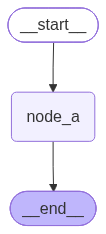

{'__interrupt__': [Interrupt(value='请输入您的姓名', id='69ea4d35f62be985586c3df77e209821', response_schema=None)]}
请输入您的姓名
{'username': 'Bob'}


In [ ]:
from typing import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver


#1. 声明状态
class OverAllState(TypedDict):
    username:str
#2. 声明节点
def node_a(state:OverAllState)->OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username":username
    }

#3. 构建图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a",node_a)
builder.add_edge(START,"node_a")
builder.add_edge("node_a",END)

#4. 想要使用中断 => 必须配置检查点
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable":{"thread_id":"123"}}
interrupt_res = graph.invoke({},config=config)
print(interrupt_res)

prompt = interrupt_res['__interrupt__'][0].value
print(prompt)
username = input(prompt)

# 5. 恢复图的中断执行
# 使用Command 传递 interrupt（上面返回的值） 需要的值
resume_res = graph.invoke(Command(resume=username),config=config)
print(resume_res)


#### 8.1.4.2 多个并行中断

**示例如下**

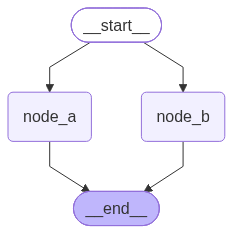

{
    '__interrupt__': [
        Interrupt(value='请输入您的姓名', id='98f8d9ebc73bd995584266350386826a', response_schema=None),
        Interrupt(value='请输入您的年龄', id='d731456efa63c418345398ac506cfbde', response_schema=None)
    ]
}

In [3]:
from typing import TypedDict
from rich import print as rprint
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int


def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username": username
    }

def node_b(state: OverAllState) -> OverAllState:
    age = interrupt("请输入您的年龄")
    return {
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}
interrupted_res = graph.invoke({}, config=config)
rprint(interrupted_res)

In [4]:
resume_map = {}

for i in interrupted_res['__interrupt__']:
    user_input = input(f"{i.value}: ")
    if "年龄" in i.value:
        resume_map[i.id] = int(user_input)
    else:
        resume_map[i.id] = user_input

resumed_res = graph.invoke(Command(resume=resume_map), config=config)
print('=' * 30, '-> resumed_res <-', '=' * 30)
rprint(resumed_res)

============================== -> resumed_res <- ==============================


{'username': 'LiHua', 'age': 22}

#### 8.1.4.3 审批模式

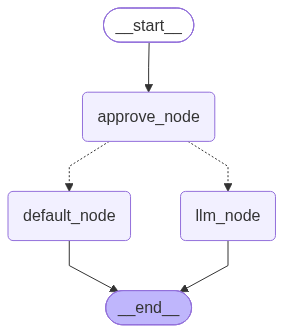

{'topic': '菊花', '__interrupt__': [Interrupt(value='是否同意调用模型?', id='6377304e0d33b9ec915a09157402c51c', response_schema=None)]}


In [ ]:
from pathlib import Path
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from time import sleep
from langgraph.checkpoint.memory import InMemorySaver
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

#1. 声明状态
class OverAllState(TypedDict):
    topic:str
    poem:str
    is_approved:bool


#2. 声明节点
def approve_node(state:OverAllState) -> Command[Literal["llm_node","default_node"]]:
    is_approved = interrupt("是否同意调用模型?")
    goto = "llm_node" if is_approved else "default_node"
    return Command(
        goto=goto,
        update={"is_approved":is_approved}
    )

def llm_node(state:OverAllState) -> OverAllState:
    topic = state["topic"]
    res = model.invoke([HumanMessage(content=f"帮我写一首关于{topic}主题的七言绝句,只写诗句,不需要赏析")]).content

    return {
        "poem":res
    }

def default_node(state:OverAllState) -> OverAllState:
    return {
        "poem":"请求被拒绝"
    }

#3. 构建图
builder = StateGraph(state_schema=OverAllState)

builder.add_node("approve_node",approve_node)
builder.add_node("llm_node",llm_node)
builder.add_node("default_node",default_node)
builder.add_edge(START,"approve_node")
builder.add_edge("llm_node",END)
builder.add_edge("default_node",END)

#4. 添加检查点后端
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

#5. 首次执行 -> 触发中断
config = {"configurable":{"thread_id":"234"}}
interrupt_res = graph.invoke({"topic":"菊花"},config=config)
print(interrupt_res)

In [7]:
print(interrupt_res['__interrupt__'][0].value)

#6. 人工审核
user_approved = input("是否同意调用模型?(y/n)").strip().lower() == 'y'
# 重新调用图
approved_res = graph.invoke(Command(resume=user_approved),config=config)
print(approved_res)

是否同意调用模型?
{'topic': '菊花', 'poem': '霜染东篱菊正黄，  \n清香一缕入诗肠。  \n孤标不与群芳竞，  \n独抱秋心傲晚凉。', 'is_approved': True}


In [10]:
#7. 审核不通过
config1 = {"configurable":{"thread_id":"123"}}
interrupt_res = graph.invoke({"topic":"牡丹花"},config=config1)
print(interrupt_res)

user_approved = input("是否同意调用模型?(y/n)").strip().lower() == 'y'
# 重新调用图
approved_res = graph.invoke(Command(resume=user_approved),config=config1)
print(approved_res)

{'topic': '牡丹花', '__interrupt__': [Interrupt(value='是否同意调用模型?', id='ac15ff4e4f2975aba5f668936f385de6', response_schema=None)]}
{'topic': '牡丹花', 'poem': '请求被拒绝', 'is_approved': False}


前一个单元格里,thread_id="234" 已经完整跑完了一轮审批(cell 10 触发中断 → cell 11 输入并恢复,状态已走到 END)。现在要测的是另一个独立场景("审核不通过"、新话题"牡丹花")。复用 "234" 会带来问题:

* 234 这个线程的状态已经"走完",不是挂起状态;带着上一轮残留的 poem / is_approved 继续跑,状态不干净;

#### 8.1.4.4 审核与编辑模式


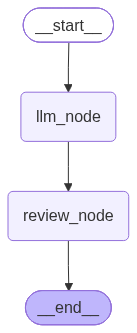

============================== -> interrupt_res <- ==============================


{
    'topic': '布偶猫',
    'poem': '蓝眸如水映窗纱  \n雪色轻裘卧落花  \n柔尾摇风招客至  \n一声细唤满庭霞',
    '__interrupt__': [
        Interrupt(
            value={
                'instruction': '请审核并修改大模型生成的七言绝句',
                'poem': '蓝眸如水映窗纱  \n雪色轻裘卧落花  \n柔尾摇风招客至  \n一声细唤满庭霞'
            },
            id='d0179ddb565a3037bfd31fde0d3d4780',
            response_schema=None
        )
    ]
}

In [13]:
from pathlib import Path
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from time import sleep
from langgraph.checkpoint.memory import InMemorySaver
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    reviewed_poem: str

def llm_node(state: OverAllState) -> OverAllState:
    topic = state['topic']

    res = model.invoke([HumanMessage(content=f"帮我写一首关于 {topic} 的七言绝句，只给出诗句，不要赏析")]).content
    return {
        "poem": res
    }

def review_node(state: OverAllState) -> OverAllState:
    reviewed_poem = interrupt({
        "instruction": "请审核并修改大模型生成的七言绝句",
        "poem": state['poem']
    })
    return {
        "reviewed_poem": reviewed_poem
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("review_node", review_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "review_node")
builder.add_edge("review_node", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "review_test"}}
interrupted_res = graph.invoke({"topic": "布偶猫"}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
rprint(interrupted_res)

In [15]:
print("原始诗句：")
print(interrupted_res['__interrupt__'][0].value['poem'])
user_review = input("请审核并修改诗句（直接回车保留原诗）: ")
if not user_review.strip():
    user_review = interrupted_res['__interrupt__'][0].value['poem']
reviewed_res = graph.invoke(Command(resume=user_review), config=config)
print('=' * 30, '-> reviewed_res <-', '=' * 30)
rprint(reviewed_res)

原始诗句：
蓝眸如水映窗纱  
雪色轻裘卧落花  
柔尾摇风招客至  
一声细唤满庭霞
============================== -> reviewed_res <- ==============================


{
    'topic': '布偶猫',
    'poem': '蓝眸如水映窗纱  \n雪色轻裘卧落花  \n柔尾摇风招客至  \n一声细唤满庭霞',
    'reviewed_poem': 'Hello World!'
}

#### 8.1.4.5 工具执行审批模式


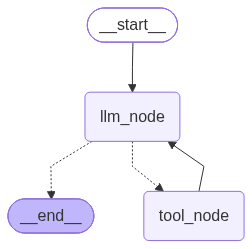

2026-10-18 20:43:19.573 | INFO     | __main__:tool_node:70 - 工具 get_weather 被调用, 对应的 tool_call: {'name': 'get_weather', 'args': {'city': '北京'}, 'id': 'call_2tUNmJwLsAYnbX5cpvbRk078', 'type': 'tool_call'}


============================== -> interrupt_res <- ==============================


{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='fd38dfe0-8982-4a12-9f4d-8d322bc5148f'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_2tUNmJwLsAYnbX5cpvbRk078',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_0e160ee834976c55016ad591d76bc087d0bb7db53694d02358',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_0e160ee834976c55016ad591d2d61487d0a6ded5ba03bbee21',
                'created_at': 1792381395.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_0e160ee834976c55016ad591d2d61487d0a6ded5ba03bbee21',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_2tUNmJwLsAYnbX5cpvbRk078',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 447,
                'output_tokens': 18,
                'total_tokens': 465,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )
    ],
    '__interrupt__': [
        Interrupt(
            value={'action': 'get_weather', 'question': '是否同意查询天气？'},
            id='64ccf38c8be9a6f67ba6fbe8d6504540',
            response_schema=None
        )
    ]
}

In [17]:
from pathlib import Path
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from time import sleep
from langgraph.checkpoint.memory import InMemorySaver
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)
@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    is_approved = interrupt({
        "action": "get_weather",
        "question": "是否同意查询天气？"
    })

    logger.info("is_approved: {}", is_approved)
    if is_approved:
        return f"{city} 今天天气不错"
    else:
        return "用户拒绝查询天气"

tools_by_name = {"get_weather": get_weather}
model_with_tools = model.bind_tools([get_weather])

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END


def tool_node(state: MessagesState) -> MessagesState:
    last_msg = state['messages'][-1]

    tool_msgs = []
    for tool_call in last_msg.tool_calls:
        tool = tools_by_name[tool_call["name"]]
        logger.info("工具 {} 被调用, 对应的 tool_call: {}", tool_call["name"], tool_call)
        tool_res = tool.invoke(tool_call["args"])
        tool_msg = ToolMessage(
            name = tool_call["name"],
            content = tool_res,
            tool_call_id = tool_call["id"]
        )
        tool_msgs.append(tool_msg)

    return {
        "messages": tool_msgs
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "tool_test"}}
interrupted_res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？")]}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
rprint(interrupted_res)

In [18]:
user_approved = input("是否同意查询天气？(y/n): ").strip().lower() == 'y'
approved_res = graph.invoke(Command(resume=user_approved), config=config)
rprint(approved_res)

2026-10-18 20:44:22.805 | INFO     | __main__:tool_node:70 - 工具 get_weather 被调用, 对应的 tool_call: {'name': 'get_weather', 'args': {'city': '北京'}, 'id': 'call_2tUNmJwLsAYnbX5cpvbRk078', 'type': 'tool_call'}
2026-10-18 20:44:22.806 | INFO     | __main__:get_weather:41 - is_approved: True


{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='fd38dfe0-8982-4a12-9f4d-8d322bc5148f'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_2tUNmJwLsAYnbX5cpvbRk078',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_0e160ee834976c55016ad591d76bc087d0bb7db53694d02358',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_0e160ee834976c55016ad591d2d61487d0a6ded5ba03bbee21',
                'created_at': 1792381395.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_0e160ee834976c55016ad591d2d61487d0a6ded5ba03bbee21',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_2tUNmJwLsAYnbX5cpvbRk078',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 447,
                'output_tokens': 18,
                'total_tokens': 465,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        ),
        ToolMessage(
            content='北京 今天天气不错',
            name='get_weather',
            id='c2a5277b-a538-469c-836f-3aeb39d43596',
            tool_call_id='call_2tUNmJwLsAYnbX5cpvbRk078'
        ),
        AIMessage(
            content=[
                {
                    'type': 'text',
                    'text': '北京今天天气不错。',
                    'annotations': [],
                    'id': 'msg_1792381467503_s9zl98633an',
                    'phase': 'final_answer'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'gen_01M5945DSN17JK1010VKXKTYX5',
                'created_at': 1792381467.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='gen_01M5945DSN17JK1010VKXKTYX5',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 88,
                'output_tokens': 9,
                'total_tokens': 97,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )
    ]
}

#### 8.1.4.6 单节点串行中断模式


In [19]:
from pathlib import Path
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from time import sleep
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str # 姓名
    age: int # 年龄
    gender: Literal["male", "female"] # 性别

def get_info_node(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的用户名：")
    age = interrupt("请输入您的年龄：")
    gender = interrupt("请输入您的性别：(male/female)")

    return {
        "username": username,
        "age": age,
        "gender": gender
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("get_info_node", get_info_node)
builder.add_edge(START, "get_info_node")
builder.add_edge("get_info_node", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "seq_interrupt_test"}}
username_interrupted_res = graph.invoke({}, config=config)

rprint(username_interrupted_res)

{
    '__interrupt__': [
        Interrupt(value='请输入您的用户名：', id='79e3c36e9d41b0ab4376c61c89958dee', response_schema=None)
    ]
}

In [20]:
user_name = input("请输入您的用户名：")
age_interrupted_res = graph.invoke(Command(resume=user_name), config=config)
rprint(age_interrupted_res)

{
    '__interrupt__': [
        Interrupt(value='请输入您的年龄：', id='79e3c36e9d41b0ab4376c61c89958dee', response_schema=None)
    ]
}

In [21]:
user_age = input("请输入您的年龄：")
gender_interrupted_res = graph.invoke(Command(resume=int(user_age)), config=config)
rprint(gender_interrupted_res)

{
    '__interrupt__': [
        Interrupt(
            value='请输入您的性别：(male/female)',
            id='79e3c36e9d41b0ab4376c61c89958dee',
            response_schema=None
        )
    ]
}

In [22]:
user_gender = input("请输入您的性别：(male/female): ")
resumed_res = graph.invoke(Command(resume=user_gender), config=config)

In [23]:
rprint(resumed_res)

{'username': 'Kate', 'age': 11, 'gender': 'male'}

### 8.1.5 使用规范
#### 8.1.5.1 不要用`try/catch`包裹`interrupt()`调用

中断的触发是通过抛出 **`GraphInterrupt`** 异常实现的，如果用 **`try/catch`** 包裹，则底层运行时无法感知断点，不会中断计算图。

#### 8.1.5.2. 不要更改单个节点内`interrupt`的调用顺序

上文提到：

1. 恢复运行时整个节点函数都会重新运行，而非精确地从断点继续
2. 同一节点中存在多个断点时：历史恢复记录被记录在检查点中，并在恢复运行时按顺序加载

一旦中断恢复前后的断点顺序、数量不完全一致，将会导致语义混乱，程序执行结果无法满足预期。

#### 8.1.5.3 不要在`interrupt()`中传递复杂类型

**`LangGraph`** 运行时会将 **`interrupt()`** 函数接收到的参数经过 **`JSON` 序列化** 之后传递给调用者。

如果传递不支持 **`JSON` 序列化** 的复杂类型，如函数、类实例，将会抛出异常

```python
TypeError: Type is not msgpack serializable: Interrupt

def validate_input(value):
    return len(value) > 0

def node_a(state: State):
    # ❌ 错误用法：传递函数
    # 函数不支持 JSON 序列化
    response = interrupt({
        "question": "What's your name?",
        "validator": validate_input  # 此处会导致失败
    })
    return {"name": response}
```

#### 8.1.5.4 断点之前的副作用操作必须是幂等的

- **副作用操作**：修改了外部环境的操作，如
  - 写数据库
  - 写文件
  - 发送邮件或消息
- **幂等性**：多次执行的结果等价于一次执行。

中断恢复时，断点所在的函数**会被重复执行**，所以，如果断点之前存在不满足幂等性的副作用操作，将会导致多次调用结果不一致。

* 断点之前
```python
def node_a(state: State):
    # ✅ 正确用法：使用幂等的 upsert 操作
    # 多次运行结果一致
    db.upsert_user(
        user_id=state["user_id"],
        status="pending_approval"
    )

    approved = interrupt("Approve this change?")

    return {"approved": approved}
```

* 断点之后
```python
def node_a(state: State):
    # ✅ 正确用法：将副作用操作放在断点之后
    # 确保副作用操作只运行一次
    approved = interrupt("Approve this change?")

    if approved:
        db.create_audit_log(
            user_id=state["user_id"],
            action="approved"
        )

    return {"approved": approved}
```

或者直接拆分成不同的节点。

### 8.1.6 中断触发和恢复前后的检查点
#### 8.1.6.1 基础HITL模式

In [3]:
from typing import TypedDict
from rich import print as rprint
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int

def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    age = interrupt("请输入您的年龄")
    return {
        "username": username,
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "123"}}
username_interrupted_res = graph.invoke({}, config=config)

rprint(username_interrupted_res)

{'__interrupt__': [Interrupt(value='请输入您的姓名', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None)]}

In [4]:
username_interrupted_his = list(graph.get_state_history(config=config))
rprint(username_interrupted_his)

[
    StateSnapshot(
        values={},
        next=('node_a',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-8710-65a0-8000-f270b220e090'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-19T07:02:22.771332+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-870e-60fc-bfff-4615152e78e5'
            }
        },
        tasks=(
            PregelTask(
                id='24c16d1d-60ab-d619-9f9d-2a1bc20a7ac8',
                name='node_a',
                path=('__pregel_pull', 'node_a'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的姓名', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None),
                ),
                state=None,
                result=None
            ),
        ),
        interrupts=(
            Interrupt(value='请输入您的姓名', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None),
        )
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-870e-60fc-bfff-4615152e78e5'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-19T07:02:22.770398+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='ec37a0b8-d382-c7d6-6e30-9b759e574970',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={}
            ),
        ),
        interrupts=()
    )
]

第一次中断，`StateSnapshot`多了`interrupts`属性。中断触发时，检查点存储器中记录的最新检查点超步为 **`0`**，中断信息只能和这个超步绑定

中断信息存了两份：

- **`StateSnapshot`** 的 **`tasks`** 属性下记录的 **`PregelTask`** 实例的 **`interrupts`** 字段记录了当前任务触发的中断信息。

- **`StateSnapshot`** 的 **`interrupts`** 属性记录了当前超步发生的所有中断

In [5]:
age_interrupted_res = graph.invoke(Command(resume="小黄"), config=config)
rprint(age_interrupted_res)

{'__interrupt__': [Interrupt(value='请输入您的年龄', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None)]}

In [6]:
age_interrupted_his = list(graph.get_state_history(config=config))
rprint(age_interrupted_his)

[
    StateSnapshot(
        values={},
        next=('node_a',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-8710-65a0-8000-f270b220e090'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-19T07:02:22.771332+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-870e-60fc-bfff-4615152e78e5'
            }
        },
        tasks=(
            PregelTask(
                id='24c16d1d-60ab-d619-9f9d-2a1bc20a7ac8',
                name='node_a',
                path=('__pregel_pull', 'node_a'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的年龄', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None),
                ),
                state=None,
                result=None
            ),
        ),
        interrupts=(
            Interrupt(value='请输入您的年龄', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None),
        )
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-870e-60fc-bfff-4615152e78e5'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-19T07:02:22.770398+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='ec37a0b8-d382-c7d6-6e30-9b759e574970',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={}
            ),
        ),
        interrupts=()
    )
]

**`checkpoint_id`、任务`id`、中断`id`** 和历史检查点完全一致，只是 **`Interrupt`** 实例的 **`value`** 属性变成了第二次中断的值。

由此可见，恢复运行时检查点的更新确实是覆盖写入，历史中断信息不会被保留。

In [7]:
resumed_res = graph.invoke(Command(resume=123), config=config)
rprint(resumed_res)

{'username': '小黄', 'age': 123}

In [8]:
resumed_his = list(graph.get_state_history(config=config))
rprint(resumed_his)

[
    StateSnapshot(
        values={'username': '小黄', 'age': 123},
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b1-e55d-69a4-8001-89e0269d909c'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-19T07:02:59.503136+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-8710-65a0-8000-f270b220e090'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('node_a',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-8710-65a0-8000-f270b220e090'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-19T07:02:22.771332+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-870e-60fc-bfff-4615152e78e5'
            }
        },
        tasks=(
            PregelTask(
                id='24c16d1d-60ab-d619-9f9d-2a1bc20a7ac8',
                name='node_a',
                path=('__pregel_pull', 'node_a'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的年龄', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None),
                ),
                state=None,
                result={'username': '小黄', 'age': 123}
            ),
        ),
        interrupts=(
            Interrupt(value='请输入您的年龄', id='3a5b0aad5a0309f2b8b6f2d313bcfe6f', response_schema=None),
        )
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8b0-870e-60fc-bfff-4615152e78e5'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-19T07:02:22.770398+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='ec37a0b8-d382-c7d6-6e30-9b759e574970',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={}
            ),
        ),
        interrupts=()
    )
]

两个断点全部恢复运行后，编号为 **`1`** 的超步终于完成，任务实例的 **`result`** 被更新，状态被更新，最后一个超步的 **`values`** 是更新后的状态值，计算图运行完成。

#### 8.1.6.2 多个并行中断触发时的检查点

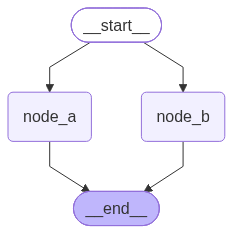

{
    '__interrupt__': [
        Interrupt(value='请输入您的年龄', id='ed1ca1d7943925c7d9554559c17be41b', response_schema=None),
        Interrupt(value='请输入您的姓名', id='aded7b59b779f5ae29b24f7bc5794838', response_schema=None)
    ]
}

In [9]:
from typing import TypedDict
from rich import print as rprint
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int

def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username": username
    }

def node_b(state: OverAllState) -> OverAllState:
    age = interrupt("请输入您的年龄")
    return {
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}
interrupted_res = graph.invoke({}, config=config)

rprint(interrupted_res)

In [10]:
rprint(list(graph.get_state_history(config=config)))

[
    StateSnapshot(
        values={},
        next=('node_a', 'node_b'),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f5-671e-8000-d3d707c3cf5e'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-19T07:36:31.153534+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f4-69ea-bfff-fd1eea29776f'
            }
        },
        tasks=(
            PregelTask(
                id='859c219c-53c4-2b64-474b-a3b6ca3d3a75',
                name='node_a',
                path=('__pregel_pull', 'node_a'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的姓名', id='aded7b59b779f5ae29b24f7bc5794838', response_schema=None),
                ),
                state=None,
                result=None
            ),
            PregelTask(
                id='126b2356-8330-3533-9821-6db1a6ca0609',
                name='node_b',
                path=('__pregel_pull', 'node_b'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的年龄', id='ed1ca1d7943925c7d9554559c17be41b', response_schema=None),
                ),
                state=None,
                result=None
            )
        ),
        interrupts=(
            Interrupt(value='请输入您的姓名', id='aded7b59b779f5ae29b24f7bc5794838', response_schema=None),
            Interrupt(value='请输入您的年龄', id='ed1ca1d7943925c7d9554559c17be41b', response_schema=None)
        )
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f4-69ea-bfff-fd1eea29776f'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-19T07:36:31.153197+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='b69f2837-e793-2912-d0ca-6d70b4808206',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={}
            ),
        ),
        interrupts=()
    )
]

In [12]:
# 6. 恢复执行
resume_map = {}
for i in interrupted_res['__interrupt__']:
    user_input = input(f"{i.value}")
    if '姓名' in i.value:
        resume_map[i.id] = user_input
    else:
        resume_map[i.id] = int(user_input)

resumed_res = graph.invoke(Command(resume=resume_map),config=config)
print(resumed_res)

{'username': 'wu', 'age': 123}


In [13]:
rprint(list(graph.get_state_history(config=config)))

[
    StateSnapshot(
        values={'username': 'wu', 'age': 123},
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb909-b9d5-6da6-8001-6d059e211529'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-19T07:42:17.170674+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f5-671e-8000-d3d707c3cf5e'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('node_a', 'node_b'),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f5-671e-8000-d3d707c3cf5e'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-19T07:36:31.153534+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f4-69ea-bfff-fd1eea29776f'
            }
        },
        tasks=(
            PregelTask(
                id='859c219c-53c4-2b64-474b-a3b6ca3d3a75',
                name='node_a',
                path=('__pregel_pull', 'node_a'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的姓名', id='aded7b59b779f5ae29b24f7bc5794838', response_schema=None),
                ),
                state=None,
                result={'username': 'wu'}
            ),
            PregelTask(
                id='126b2356-8330-3533-9821-6db1a6ca0609',
                name='node_b',
                path=('__pregel_pull', 'node_b'),
                error=None,
                interrupts=(
                    Interrupt(value='请输入您的年龄', id='ed1ca1d7943925c7d9554559c17be41b', response_schema=None),
                ),
                state=None,
                result={'age': 123}
            )
        ),
        interrupts=(
            Interrupt(value='请输入您的姓名', id='aded7b59b779f5ae29b24f7bc5794838', response_schema=None),
            Interrupt(value='请输入您的年龄', id='ed1ca1d7943925c7d9554559c17be41b', response_schema=None)
        )
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cb8fc-d5f4-69ea-bfff-fd1eea29776f'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-19T07:36:31.153197+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='b69f2837-e793-2912-d0ca-6d70b4808206',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={}
            ),
        ),
        interrupts=()
    )
]

底层负责执行节点逻辑的是超步的第二阶段，如果存在多个并行任务，则会将任务提交到线程池，在独立的线程中运行，负责执行第二阶段的 **`PregelRunner`** 实例会收集提交后的 **`future`** 对象，并等待所有任务完成。

当中断触发时，对应的线程会抛出 **`GraphInterrupt`**，对应的 **`future`** 对象会收集异常。

**`PregelRunner`** 实例在 **`future`** 对应的任务完成后，收集中断信息或任务执行结果，写入检查点存储器。

所以一个超步中某个任务触发中断，不会导致其它并行任务的终止，正常运行的任务结果、中断任务的中断信息都被记录在检查点后端。

# 问题

### 1. 为什么已经被恢复的 interrupt()不会被重复触发？

**`interrupt()` 会先查找对应的恢复值：有值就直接返回，找不到才触发暂停。**

因此，“已经被恢复的 `interrupt()` 不会被重复触发”更准确地说是：**恢复时，`interrupt()` 仍然会被再次调用，只是已经得到回答的调用不会再次暂停。**

结合上方的节点代码：

```python
def get_info_node(state):
    username = interrupt("请输入您的用户名：")          # 第 0 次调用
    age = interrupt("请输入您的年龄：")                # 第 1 次调用
    gender = interrupt("请输入您的性别：(male/female)") # 第 2 次调用

    return {"username": username, "age": age, "gender": gender}
```

LangGraph 为**当前节点任务（task）**维护一份按顺序排列的恢复值记录，并通过检查点机制保存这些信息。每次使用相同的 `thread_id` 恢复该任务时：

1. **从头执行节点函数**，本轮的 `interrupt` 调用索引重新从 `0` 开始。
2. 每遇到一次 `interrupt()`，先用调用索引查找历史恢复值，找到就直接返回。
3. 历史值用完后，使用本次 `Command(resume=...)` 传入的恢复值，并将它追加到恢复记录。
4. 后续再遇到没有恢复值的 `interrupt()`，才抛出 `GraphInterrupt`，由运行时处理并暂停图的执行。

沿用本笔记上方实际运行结果中的输入 `"Kate"`、`11`、`"male"`，执行过程如下：

| 调用图 | 用户名处 | 年龄处 | 性别处 |
| --- | --- | --- | --- |
| 首次 `graph.invoke({}, config=config)` | 没有恢复值，暂停 | 未执行 | 未执行 |
| `Command(resume="Kate")` | 返回本次输入 `"Kate"` | 没有恢复值，暂停 | 未执行 |
| `Command(resume=11)` | 返回历史值 `"Kate"` | 返回本次输入 `11` | 没有恢复值，暂停 |
| `Command(resume="male")` | 返回历史值 `"Kate"` | 返回历史值 `11` | 返回本次输入 `"male"`，节点完成 |

例如，第三轮调用图时，历史恢复记录可以理解为：

```python
resume_values = ["Kate"]
# 本次新传入的恢复值是 11
```

节点从头执行，用户名处的调用索引是 `0`，所以直接返回历史值 `resume_values[0]`，得到 `"Kate"`，不会暂停。随后年龄处的调用索引是 `1`，历史记录中没有这一项，于是接收本次输入 `11`，恢复记录变成：

```python
resume_values = ["Kate", 11]
```

再往下执行到性别处，调用索引是 `2`，既没有对应的历史值，也没有尚未使用的本次恢复值，这时才暂停。

当前安装的 LangGraph 1.2.14 在 `langgraph/types.py` 的 `interrupt()` 实现中，处理顺序就是：先通过 `scratchpad.interrupt_counter()` 获取本轮调用索引，再查找 `scratchpad.resume` 中的历史值，然后查找本次恢复值，最后才抛出 `GraphInterrupt`。

这带来几个需要注意的地方：

- **各次 `interrupt()` 的执行顺序必须稳定。** 历史值按实际调用索引匹配，不根据提示文本、变量名或源码行号匹配。改变调用顺序，可能让用户名被当成年龄。
- **节点中的普通代码仍然会重复执行。** 如果在节点开头加一句 `print("进入节点")`，上述完整流程会打印四次；局部变量 `username` 也是每轮通过 `interrupt()` 的返回值重新赋值的。保存恢复值并不等于保存 Python 函数的调用栈和局部变量。
- **恢复记录属于当前任务。** 节点完成后，如果图中的循环再次调度同名节点，产生的是新的任务，不能理解为这个节点的中断以后都会被永久跳过。

参考：[LangGraph 官方文档：不要改变节点内 interrupt 调用的顺序](https://docs.langchain.com/oss/python/langgraph/interrupts#do-not-reorder-interrupt-calls-within-a-node)。
